<div style="background:linear-gradient(135deg,#123524 0%,#1f5a45 45%,#2B5A82 100%);color:#fff;padding:40px 36px;border-radius:16px;font-family:system-ui,-apple-system,'Segoe UI',sans-serif">
  <div style="font-size:12px;letter-spacing:.16em;opacity:.75;text-transform:uppercase">43008 Reinforcement Learning &middot; Assignment 3 &middot; Team LMF</div>
  <div style="font-size:46px;font-weight:800;line-height:1.05;margin:12px 0 6px">Experiment: PPO</div>
  <div style="font-size:19px;opacity:.92">Proximal Policy Optimisation on AgriFlight-RL, crop-row flight stabilisation</div>
  <div style="height:1px;background:rgba(255,255,255,.28);margin:24px 0 18px"></div>
  <div style="display:flex;flex-wrap:wrap;gap:36px">
    <div><div style="font-size:11px;letter-spacing:.12em;opacity:.7;text-transform:uppercase">Student</div><div style="font-size:20px;font-weight:600">Nelkit Isael Chavez Calona</div></div>
    <div><div style="font-size:11px;letter-spacing:.12em;opacity:.7;text-transform:uppercase">Student ID</div><div style="font-size:20px;font-weight:600">25609227</div></div>
    <div><div style="font-size:11px;letter-spacing:.12em;opacity:.7;text-transform:uppercase">Environment</div><div style="font-size:20px;font-weight:600">AgroDrone-v0 &middot; MuJoCo Skydio X2</div></div>
  </div>
</div>

### Contents

1. [Introduction](#intro): question, hypothesis, success criterion
2. [Setup](#setup): environment, config, seeds, shared helpers
3. [Theory](#theory): the algorithm in your own words
4. [Implementation](#implementation): the code
5. [Training](#training): run, curve, stability
6. [Evaluation](#evaluation): held-out seeds, baselines, difficulty levels
7. [Results](#results): table and plots
8. [Discussion](#discussion): what worked, what did not, limits
9. [Contribution and reproducibility](#contribution): who did what, versions, references

<div style="border-left:4px solid rgb(140,90,43);background:rgba(140,90,43,0.10);padding:10px 14px;border-radius:0 8px 8px 0;margin:6px 0"><b>Template status (delete this box before submitting).</b> <code>Run all</code> works today and produces the baseline numbers. Cells marked <i>Write here</i> or <code>TODO</code> are yours. Do not edit the cells labelled <i>Shared, identical in all three notebooks</i>: the comparison is only fair if they stay the same.</div>

<a id="intro"></a>

## 1. Introduction

<div style="border-left:4px solid rgb(147,105,28);background:rgba(147,105,28,0.10);padding:10px 14px;border-radius:0 8px 8px 0;margin:6px 0"><b>Write here.</b> In about 150 words:<ul><li>The research question this notebook answers (not "train a drone")</li><li>What PPO is, in two sentences</li><li>Your hypothesis. Part B expects PPO to be the most stable of the three. Say whether you agree, and what result would change your mind.</li><li><b>Your success criterion, written before you see results</b>: the highest difficulty level you expect to clear (L0 to L4) and roughly how many samples it needs</li></ul></div>

<a id="setup"></a>

## 2. Setup

**2.1 Bootstrap.** Finds the repo (or clones it), fetches the Skydio X2 model from the public MuJoCo Menagerie and installs any missing dependencies. Works on **AWS SageMaker**, **Google Colab** and a local Jupyter. Nothing to edit.

<details>
<summary><b>First time on SageMaker? Click here: GitHub token + clone the repo (one-off, about 5 minutes)</b></summary>

The repo is **private**, so SageMaker needs a GitHub *personal access token* to clone it. Each team member creates their own.

**A. Create a fine-grained token on GitHub**
1. GitHub (top-right avatar) → **Settings** → **Developer settings** → **Personal access tokens** → **Fine-grained tokens** → **Generate new token**.
2. *Token name*: `sagemaker-agroflight`. *Expiration*: 30 days (covers the project).
3. *Resource owner*: `Nelkit`. *Repository access*: **Only select repositories** → `agroflight-rl`. (If `Nelkit` is not in the list, ask Nelkit to confirm you are a collaborator; a classic token with the `repo` scope also works.)
4. *Permissions* → *Repository permissions* → **Contents: Read and write** (write lets you push your results).
5. **Generate token** and copy it (`github_pat_...`). GitHub shows it only once. Never paste it into a notebook cell or commit it.

**B. Clone the repo in SageMaker (from a Terminal, not from a notebook cell)**

In SageMaker Studio / JupyterLab: *File → New → Terminal*, then:
```bash
cd ~
git clone https://<YOUR_TOKEN>@github.com/Nelkit/agroflight-rl.git
cd agroflight-rl
git remote set-url origin https://github.com/Nelkit/agroflight-rl.git   # keep the token out of .git/config
git config user.name  "Your Name"
git config user.email "your.email@student.uts.edu.au"
git config credential.helper store                                     # asks for the token once on the next pull/push
git checkout -b <yourname>/<topic>                                       # one branch per person, e.g. nelkit/ppo-l0
```
When `git pull`/`git push` asks: *Username* = your GitHub user, *Password* = the token.

**C. Run**
1. Open `~/agroflight-rl/notebooks/<this notebook>.ipynb` and pick a **PyTorch** kernel (CPU is fine for Stage 1).
2. Run this cell. It detects the clone, so no token is needed here.
3. Get the latest code at any time with `git pull` in the Terminal. Commit `results/*.json` and your notebook on your branch; checkpoints (`*.pt`) are git-ignored and stay in your SageMaker home.

**Colab or a notebook opened outside the clone:** this cell clones the repo itself. It reads the token from the `GITHUB_TOKEN` environment variable, from Colab *Secrets* (key icon → add `GITHUB_TOKEN`), or asks for it with a hidden prompt. On a local machine it never prompts: if the notebook is not inside a clone, the cell stops with a message saying what to do. The token is not saved in the notebook or in `.git/config`.

Full guide: `docs/sagemaker_setup.md`.
</details>

In [1]:
import os, sys, subprocess, time, importlib, importlib.util
NOTEBOOK_T0 = time.time()

IN_COLAB = "google.colab" in sys.modules
IN_SAGEMAKER = bool(
    os.environ.get("SAGEMAKER_INTERNAL_IMAGE_URI") or os.environ.get("SM_CURRENT_HOST")
    or os.path.isdir("/opt/ml/metadata") or os.path.expanduser("~") == "/home/sagemaker-user"
)
PLATFORM = "colab" if IN_COLAB else ("sagemaker" if IN_SAGEMAKER else "local")

REPO_URL = "github.com/Nelkit/agroflight-rl.git"   # private repo: needs a GitHub token (see 2.1)
BRANCH = "main"                                    # only used if this cell has to clone the repo itself
CLONE_DIR = "/content/agroflight-rl" if IN_COLAB else os.path.expanduser("~/agroflight-rl")

def run(cmd, cwd=None):
    subprocess.run(cmd, cwd=cwd, check=True)

def find_repo_root(start):
    p = os.path.abspath(start)
    while True:
        if os.path.isfile(os.path.join(p, "pyproject.toml")):
            return p
        parent = os.path.dirname(p)
        if parent == p:
            return None
        p = parent

# 1. Repo: this notebook's own clone, an existing clone in CLONE_DIR, or clone it now.
#    Search upwards from the notebook file (VS Code exposes its path) and from the kernel's
#    working directory, so a kernel started outside the repo still finds it.
_nb_file = globals().get("__vsc_ipynb_file__")   # set by VS Code, None elsewhere
_starts = ([os.path.dirname(_nb_file)] if _nb_file else []) + [os.getcwd()]
REPO = next((r for r in map(find_repo_root, _starts) if r), None)
if REPO is None and os.path.isfile(os.path.join(CLONE_DIR, "pyproject.toml")):
    REPO = CLONE_DIR
if REPO is None:
    token = os.environ.get("GITHUB_TOKEN")
    if not token and IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token and PLATFORM == "local":
        # Never prompt on a local machine: in VS Code the prompt is easy to miss and the cell looks hung.
        raise RuntimeError(
            f"agroflight-rl repo not found from {os.getcwd()}. Open this notebook from inside your "
            f"clone and restart the kernel, or set GITHUB_TOKEN to let this cell clone it into {CLONE_DIR}.")
    if not token:
        from getpass import getpass
        token = getpass("GitHub token for the private repo (hidden, not stored): ").strip()
    if not token:
        raise RuntimeError("No GitHub token given, so the private repo cannot be cloned. See 2.1.")
    # GIT_TERMINAL_PROMPT=0: a wrong token fails straight away instead of waiting for a password.
    subprocess.run(["git", "clone", "--quiet", "--branch", BRANCH, f"https://{token}@{REPO_URL}", CLONE_DIR],
                   check=True, env={**os.environ, "GIT_TERMINAL_PROMPT": "0"})
    run(["git", "remote", "set-url", "origin", "https://" + REPO_URL], cwd=CLONE_DIR)  # drop the token
    del token
    REPO = CLONE_DIR
os.chdir(REPO)

# 2. Drone model: Skydio X2 from the public google-deepmind/mujoco_menagerie (sparse clone, a few MB).
DRONE_XML = os.path.join(REPO, "mujoco_menagerie", "skydio_x2", "x2.xml")
if not os.path.isfile(DRONE_XML):
    if not os.path.isdir("mujoco_menagerie"):
        run(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse",
             "https://github.com/google-deepmind/mujoco_menagerie.git", "mujoco_menagerie"])
    run(["git", "sparse-checkout", "set", "skydio_x2"], cwd="mujoco_menagerie")
os.environ["AGRO_DRONE_XML"] = DRONE_XML

# 3. Dependencies: install the project (+ torch, matplotlib, pandas) only if something is missing.
if any(importlib.util.find_spec(m) is None for m in ("mujoco", "gymnasium", "torch", "matplotlib", "pandas")):
    run([sys.executable, "-m", "pip", "install", "-q", "-e", ".[train]"])
    importlib.invalidate_caches()
sys.path.insert(0, os.path.join(REPO, "src"))
import mujoco, gymnasium   # also used by the reproducibility cell in Section 9

_head = subprocess.run(["git", "log", "-1", "--format=%h (%ad)", "--date=short"], cwd=REPO,
                       capture_output=True, text=True).stdout.strip()
_branch = subprocess.run(["git", "rev-parse", "--abbrev-ref", "HEAD"], cwd=REPO,
                         capture_output=True, text=True).stdout.strip()
print("platform:", PLATFORM)
print("repo    :", REPO, "| branch", _branch, "| commit", _head)
print("model   :", DRONE_XML)

platform: local
repo    : /Users/nelkitchavezcalona/Projects/UTS/RL/Reinforcement Learning - AT3/agroflight-rl | branch nelkit/ppo-algorithm | commit 3bc550f (2026-09-30)
model   : /Users/nelkitchavezcalona/Projects/UTS/RL/Reinforcement Learning - AT3/agroflight-rl/mujoco_menagerie/skydio_x2/x2.xml


**2.2 Experiment config and seeds.** Training seeds start at 0. Evaluation seeds start at 1000, so they are held out from training.

In [2]:
import random
import numpy as np
import torch

EXPERIMENT = dict(
    algorithm="PPO",
    student_name="Nelkit Isael Chavez Calona",
    student_id="25609227",
    env_id="AgroDrone-v0",
    train_seed=0,
    eval_seeds=list(range(1000, 1020)),
    level=0,   # start at L0; move up only when it works
)
BACKUP_TO_DRIVE = False   # set True in Colab to copy results and checkpoints to Google Drive (survives the runtime)

HPARAMS = dict(
    total_timesteps=200_000,   # starting guess, not tuned
    learning_rate=3e-4,
    gamma=0.99,
    gae_lambda=0.95,
    num_steps=2048,
    num_minibatches=32,
    update_epochs=10,
    clip_coef=0.2,
    ent_coef=0.0,
    vf_coef=0.5,
    max_grad_norm=0.5,
    hidden=(64, 64),
)

random.seed(EXPERIMENT["train_seed"])
np.random.seed(EXPERIMENT["train_seed"])
torch.manual_seed(EXPERIMENT["train_seed"])
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

device: cpu


**2.3 Shared, identical in all three notebooks. Do not edit.** Results file schema (so one comparison notebook can read all three), checkpoint save and load (the viewer loads these), Drive backup, and the learning-curve plot.

In [3]:
import json, datetime, subprocess, shutil
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

RESULTS_DIR = os.path.join(REPO, "results")
CHECKPOINT_DIR = os.path.join(REPO, "checkpoints")

def git_commit():
    try:
        return subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], cwd=REPO, text=True).strip()
    except Exception:
        return None

def new_results():
    return dict(
        schema=1,
        algorithm=EXPERIMENT["algorithm"],
        student=dict(name=EXPERIMENT["student_name"], id=EXPERIMENT["student_id"]),
        env_id=EXPERIMENT["env_id"],
        git_commit=git_commit(),
        created=datetime.datetime.now().isoformat(timespec="seconds"),
        hparams=HPARAMS,
        training=dict(train_seed=EXPERIMENT["train_seed"], total_timesteps=None, wall_clock_s=None,
                      best_checkpoint=None, curve=[]),   # curve: list of {"timesteps": int, "mean_return": float}
        evaluation=dict(eval_seeds=EXPERIMENT["eval_seeds"], baselines={}, levels={}),
    )

def save_results(results):
    os.makedirs(RESULTS_DIR, exist_ok=True)
    path = os.path.join(RESULTS_DIR, f"{EXPERIMENT['algorithm'].lower()}_{EXPERIMENT['student_id']}.json")
    with open(path, "w") as f:
        json.dump(results, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
    return path

def save_checkpoint(model, obs_dim, act_dim, tag="best"):
    os.makedirs(CHECKPOINT_DIR, exist_ok=True)
    path = os.path.join(CHECKPOINT_DIR, f"{EXPERIMENT['algorithm'].lower()}_{EXPERIMENT['student_id']}_{tag}.pt")
    torch.save(dict(algorithm=EXPERIMENT["algorithm"], student_id=EXPERIMENT["student_id"], hparams=HPARAMS,
                    obs_dim=obs_dim, act_dim=act_dim, state_dict=model.state_dict()), path)
    return path

def load_checkpoint(model, tag="best"):
    path = os.path.join(CHECKPOINT_DIR, f"{EXPERIMENT['algorithm'].lower()}_{EXPERIMENT['student_id']}_{tag}.pt")
    ckpt = torch.load(path, map_location="cpu")
    model.load_state_dict(ckpt["state_dict"])
    return ckpt

def backup_to_drive(dirs):
    if not IN_COLAB:
        print("Not in Colab: nothing to back up.")
        return
    from google.colab import drive
    drive.mount("/content/drive")
    dest = "/content/drive/MyDrive/agroflight"
    os.makedirs(dest, exist_ok=True)
    for d in dirs:
        if os.path.isdir(d):
            shutil.copytree(d, os.path.join(dest, os.path.basename(d)), dirs_exist_ok=True)
    print("backed up to", dest)

def plot_learning_curve(curve, window=10):
    xs = [p["timesteps"] for p in curve]
    ys = np.array([p["mean_return"] for p in curve], dtype=float)
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.plot(xs, ys, alpha=0.35, label="mean return")
    if len(ys) >= window:
        smooth = np.convolve(ys, np.ones(window) / window, mode="valid")
        ax.plot(xs[window - 1:], smooth, linewidth=2, label=f"moving average ({window})")
    ax.set_xlabel("environment steps")
    ax.set_ylabel("episode return")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.show()

RESULTS = new_results()

**2.4 Environment check.** One reset and one random step, to confirm the model loads.

In [4]:
import gymnasium as gym
import agroflight.envs
from agroflight.envs import ENV_ID

env = gym.make(ENV_ID, level=EXPERIMENT["level"])
obs, _ = env.reset(seed=EXPERIMENT["train_seed"])
print("observation:", env.observation_space.shape, "| action:", env.action_space.shape)
obs, r, terminated, truncated, info = env.step(env.action_space.sample())
print("one random step -> reward", round(r, 3), "| crashed:", info["crashed"])
env.close()

observation: (14,) | action: (4,)
one random step -> reward 0.009 | crashed: False


<a id="theory"></a>

## 3. Theory

<div style="border-left:4px solid rgb(147,105,28);background:rgba(147,105,28,0.10);padding:10px 14px;border-radius:0 8px 8px 0;margin:6px 0"><b>Write here.</b> Explain PPO in your own words, as if teaching a teammate. Cover:<ul><li>What the probability ratio $r_t(\theta)$ measures, and what the clip does to it</li><li>Why clipping approximates a trust region without second-order maths</li><li>Generalised Advantage Estimation (GAE): what $\lambda$ trades off</li><li>Why PPO reuses each batch for several epochs, and why that is safe here</li><li>Which implementation details CleanRL adds beyond the paper (for example advantage normalisation and learning-rate annealing)</li><li>Gaussian policy head for the continuous action space</li></ul>Add short pseudocode. The oral defence asks about exactly this section.</div>

Core objective, as a starting point to explain (not a substitute for the explanation):

$$L^{CLIP}(\theta)=\mathbb{E}_t\Big[\min\big(r_t(\theta)\hat A_t,\ \mathrm{clip}(r_t(\theta),1-\epsilon,1+\epsilon)\hat A_t\big)\Big],\qquad r_t(\theta)=\frac{\pi_\theta(a_t\mid s_t)}{\pi_{\theta_{old}}(a_t\mid s_t)}$$

<a id="implementation"></a>

## 4. Implementation

Adapt CleanRL's single-file `ppo_continuous_action.py` (to be copied into `src/agroflight/training/`, because the pip `cleanrl` 0.4.8 wrapper fails on import). Read it line by line and explain each block in your own words; the explanation is what gets marked at the oral defence.

In [5]:
import numpy as np
import torch
import torch.nn as nn
from torch.distributions import Normal

def layer_init(layer, std=np.sqrt(2), bias_const=0.0):
    torch.nn.init.orthogonal_(layer.weight, std)
    torch.nn.init.constant_(layer.bias, bias_const)
    return layer

class Agent(nn.Module):
    """Actor-critic for PPO: obs -> action distribution and obs -> value."""
    def __init__(self, obs_dim, act_dim, hidden=HPARAMS["hidden"]):
        super().__init__()
        h1, h2 = hidden
        self.critic = nn.Sequential(
            layer_init(nn.Linear(obs_dim, h1)), nn.Tanh(),
            layer_init(nn.Linear(h1, h2)),      nn.Tanh(),
            layer_init(nn.Linear(h2, 1), std=1.0),
        )
        self.actor_mean = nn.Sequential(
            layer_init(nn.Linear(obs_dim, h1)), nn.Tanh(),
            layer_init(nn.Linear(h1, h2)),      nn.Tanh(),
            layer_init(nn.Linear(h2, act_dim), std=0.01),
        )
        self.actor_logstd = nn.Parameter(torch.zeros(1, act_dim))


    def get_value(self, obs):
        return self.critic(obs)

    def get_action_and_value(self, obs, action=None):
        action_mean = self.actor_mean(obs)  
        action_std = self.actor_logstd.expand_as(action_mean).exp()
        dist = Normal(action_mean, action_std) 
        if action is None:
            action = dist.sample()
        return (action, dist.log_prob(action).sum(1), dist.entropy().sum(1), self.critic(obs))


def compute_gae(rewards, values, dones, next_value, gamma, gae_lambda):
    """rewards, values, dones: tensors (T,). dones[t]=1 if the episode ended after action t.
    next_value: V(s_T), the state following the last step in the buffer."""
    T = len(rewards)
    advantages = torch.zeros_like(rewards)
    lastgaelam = 0.0
    for t in reversed(range(T)):
        next_v = next_value if t == T - 1 else values[t + 1]
        nonterminal = 1.0 - dones[t]
        delta = rewards[t] + gamma * next_v * nonterminal - values[t]
        lastgaelam = delta + gamma * gae_lambda * nonterminal * lastgaelam
        advantages[t] = lastgaelam
    returns = advantages + values
    return advantages, returns

def ppo_update(agent, optimizer, batch):
    """batch: dict of flat tensors of length B = num_steps:
    obs (B, 14), actions (B, 4), logprobs (B,), advantages (B,), returns (B,)."""
    B = batch["obs"].shape[0]
    mb_size = B // HPARAMS["num_minibatches"]
    clip = HPARAMS["clip_coef"]
    clipfracs = []

    for epoch in range(HPARAMS["update_epochs"]):
        idx = torch.randperm(B)
        for start in range(0, B, mb_size):
            mb = idx[start:start + mb_size]

            # A: re-evaluate the STORED actions under the current policy
            _, newlogprob, entropy, newvalue = agent.get_action_and_value(batch["obs"][mb], batch["actions"][mb])
            newvalue = newvalue.view(-1)   # (mb, 1) -> (mb,), avoids a silent (mb, mb) broadcast

            # B: probability ratio pi_new / pi_old, computed in log space
            logratio = newlogprob - batch["logprobs"][mb]
            ratio = logratio.exp()

            # C: diagnostics only, no gradient
            with torch.no_grad():
                approx_kl = ((ratio - 1) - logratio).mean()
                clipfracs.append(((ratio - 1.0).abs() > clip).float().mean().item())

            # D: normalise advantages per minibatch (local copy, the batch is not modified)
            mb_adv = batch["advantages"][mb]
            mb_adv = (mb_adv - mb_adv.mean()) / (mb_adv.std() + 1e-8)

            # E: clipped surrogate; negated because the optimiser minimises, so min becomes max
            pg_loss1 = -mb_adv * ratio
            pg_loss2 = -mb_adv * torch.clamp(ratio, 1.0 - clip, 1.0 + clip)
            pg_loss = torch.max(pg_loss1, pg_loss2).mean()

            # F: value loss (plain MSE, no value clipping)
            v_loss = 0.5 * ((newvalue - batch["returns"][mb]) ** 2).mean()
            entropy_loss = entropy.mean()

            # G: total loss, backward, gradient clipping, optimiser step
            loss = pg_loss - HPARAMS["ent_coef"] * entropy_loss + HPARAMS["vf_coef"] * v_loss
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(agent.parameters(), HPARAMS["max_grad_norm"])
            optimizer.step()

    return dict(pg_loss=pg_loss.item(), v_loss=v_loss.item(), entropy=entropy_loss.item(),
                approx_kl=approx_kl.item(), clipfrac=float(np.mean(clipfracs)))


<a id="training"></a>

## 5. Training

<div style="border-left:4px solid rgb(147,105,28);background:rgba(147,105,28,0.10);padding:10px 14px;border-radius:0 8px 8px 0;margin:6px 0"><b>Write here.</b> Describe the training setup: the difficulty level (start at L0 and only move up when it is solved), hyperparameters and why, wall-clock time per 1M steps (Part B asks Stage 1 to calibrate this), and at least 3 seeds for the stability comparison.</div>

In [6]:
def train_ppo(seed=EXPERIMENT["train_seed"], level=EXPERIMENT["level"],
              total_timesteps=HPARAMS["total_timesteps"], tag="best"):
    """Train PPO on the AgroDrone-v0 environment."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    env = gym.make(ENV_ID, level=level)
    obs_dim = env.observation_space.shape[0]
    act_dim = env.action_space.shape[0]
    agent = Agent(obs_dim, act_dim).to(DEVICE)
    # eps=1e-5 follows CleanRL; must be identical across ablation runs
    optimizer = torch.optim.Adam(agent.parameters(), lr=HPARAMS["learning_rate"], eps=1e-5)

    T = HPARAMS["num_steps"]
    num_updates = total_timesteps // T
    obs_buf = torch.zeros((T, obs_dim), dtype=torch.float32, device=DEVICE)
    act_buf = torch.zeros((T, act_dim), dtype=torch.float32, device=DEVICE)
    logp_buf, rew_buf, done_buf, val_buf = (torch.zeros((T,), dtype=torch.float32, device=DEVICE) for _ in range(4))

    # Per-episode trackers
    curve, history = [], []
    recent_returns, recent_lengths, recent_crashes = [], [], []
    best_returns, best_ckpt_path = -np.inf, None
    ep_return, ep_len, global_step, t0 = 0.0, 0, 0, time.time()
    next_obs, _ = env.reset(seed=seed)

    for update in range(1, num_updates + 1):
        lr = HPARAMS["learning_rate"] * (1 - (update - 1) / num_updates)
        for param_group in optimizer.param_groups:
            param_group["lr"] = lr

        for t in range(T):
            global_step += 1
            obs_t = torch.as_tensor(next_obs, dtype=torch.float32)
            with torch.no_grad():
                obs_buf[t] = obs_t.to(DEVICE)
                action, logprob, _, value = agent.get_action_and_value(obs_buf[t].unsqueeze(0))
                act_buf[t] = action.cpu()
                logp_buf[t] = logprob.cpu()
                val_buf[t] = value.cpu()
            # Keep info: it carries the crash flag
            next_obs, reward, terminated, truncated, info = env.step(act_buf[t].cpu().numpy())
            done = terminated or truncated
            rew_buf[t] = reward
            done_buf[t] = done
            ep_return += reward
            ep_len += 1
            if done:
                # Store episode metrics and reset counters
                recent_returns.append(ep_return)
                recent_lengths.append(ep_len)
                recent_crashes.append(float(bool(info.get("crashed", False))))
                ep_return, ep_len = 0.0, 0
                next_obs, _ = env.reset()

        with torch.no_grad():
            next_value = agent.get_value(torch.as_tensor(next_obs, dtype=torch.float32).unsqueeze(0)).cpu()
        advantages, returns = compute_gae(rewards=rew_buf, values=val_buf, dones=done_buf, next_value=next_value,
                                          gamma=HPARAMS["gamma"], gae_lambda=HPARAMS["gae_lambda"])
        stats = ppo_update(agent, optimizer, dict(obs=obs_buf, actions=act_buf, logprobs=logp_buf, values=val_buf,
                                                  advantages=advantages, returns=returns))
        if recent_returns:
            mean_return = float(np.mean(recent_returns[-10:]))
            mean_length = float(np.mean(recent_lengths[-10:]))
            crash_rate = float(np.mean(recent_crashes[-10:]))

            # curve keeps the schema shared across notebooks (do not modify)
            curve.append({"timesteps": global_step, "mean_return": mean_return})
            # history holds every logged metric, for plots and the ablation
            history.append(dict(timesteps=global_step, mean_return=mean_return,
                                mean_length=mean_length, crash_rate=crash_rate, **stats))

            print(f"update {update}/{num_updates} | steps {global_step} | mean return {mean_return:.2f} | "
                  f"ep_len {mean_length:.1f} | crash {crash_rate:.0%} | "
                  f"pg_loss {stats['pg_loss']:.3f} | v_loss {stats['v_loss']:.3f} | "
                  f"entropy {stats['entropy']:.3f} | approx_kl {stats['approx_kl']:.5f} | "
                  f"clipfrac {stats['clipfrac']:.3f}")
            if mean_return > best_returns:
                best_returns = mean_return
                # Local only: the caller decides whether this goes into RESULTS
                best_ckpt_path = save_checkpoint(agent, obs_dim, act_dim, tag=tag)
                print(f"New best checkpoint saved ({tag}).")
    env.close()
    return agent, curve, history, best_ckpt_path, time.time() - t0

**5.1 Baseline run: 1M steps, no reward normalisation.** One full training run with the CleanRL hyperparameters from 2.2. It is the reference for the reward-normalisation ablation, and its wall-clock time is the Stage 1 calibration Part B asks for. The best checkpoint (by training return, never by the evaluation seeds) is saved under `RUN_TAG`, and this run is registered in `RESULTS`.

In [7]:
RUN_TAG = "base_1M"   # checkpoint name for this run; Section 6 loads the same tag

agent_base, curve_base, hist_base, ckpt_base, wall_base = train_ppo(total_timesteps=1_000_000, tag=RUN_TAG)
print(f"wall-clock: {wall_base:.0f} s ({wall_base / 60:.1f} min per 1M steps)")

# Register this run as the official one in the shared results file
RESULTS["training"].update(curve=curve_base, total_timesteps=1_000_000,
                           wall_clock_s=wall_base, best_checkpoint=ckpt_base)

# Save the full history to disk: if the kernel dies, the run is not lost
os.makedirs(RESULTS_DIR, exist_ok=True)
with open(os.path.join(RESULTS_DIR, "ppo_ablation_base_1M.json"), "w") as f:
    json.dump(dict(wall_s=wall_base, history=hist_base), f)


update 1/488 | steps 2048 | mean return -113.68 | ep_len 123.0 | crash 100% | pg_loss -0.013 | v_loss 75.923 | entropy 5.723 | approx_kl 0.00792 | clipfrac 0.072
New best checkpoint saved (base_1M).
update 2/488 | steps 4096 | mean return -114.74 | ep_len 123.2 | crash 100% | pg_loss -0.031 | v_loss 109.646 | entropy 5.729 | approx_kl 0.00816 | clipfrac 0.050
update 3/488 | steps 6144 | mean return -117.76 | ep_len 120.4 | crash 100% | pg_loss -0.013 | v_loss 74.673 | entropy 5.718 | approx_kl 0.00801 | clipfrac 0.053
update 4/488 | steps 8192 | mean return -113.40 | ep_len 126.0 | crash 100% | pg_loss -0.022 | v_loss 66.684 | entropy 5.680 | approx_kl 0.00590 | clipfrac 0.047
New best checkpoint saved (base_1M).
update 5/488 | steps 10240 | mean return -115.62 | ep_len 124.2 | crash 100% | pg_loss -0.033 | v_loss 20.401 | entropy 5.693 | approx_kl 0.00598 | clipfrac 0.071
update 6/488 | steps 12288 | mean return -116.47 | ep_len 124.0 | crash 100% | pg_loss 0.010 | v_loss 22.124 | ent

**5.2 Training diagnostics.** Four panels, each a moving average over updates:
- **Episode return**: the learning curve itself.
- **Episode length** and **crash rate**: whether the agent survives. A return that drops while length rises means the agent is learning to survive before it learns to fly precisely.
- **Value loss** (log scale): how well the critic predicts returns. A very large value loss takes most of the gradient budget away from the actor.

Pass several runs in the dictionary to overlay them (used for the ablation).

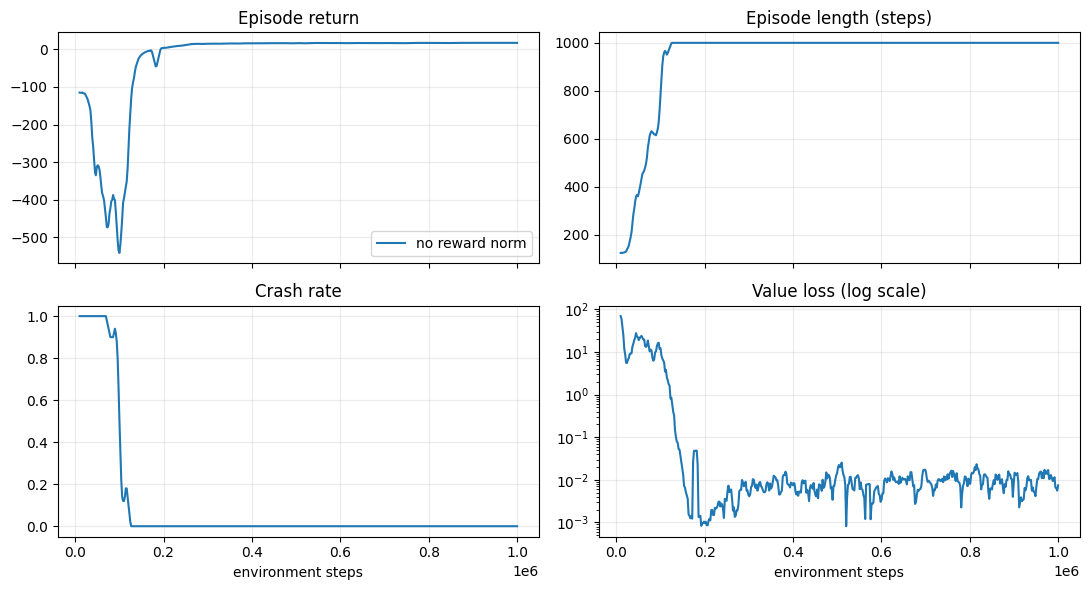

In [8]:
def plot_training_history(runs, window=5):
    """runs: {label: history}. One line per run on 4 diagnostic panels (moving average)."""
    panels = [("mean_return", "Episode return"), ("mean_length", "Episode length (steps)"),
              ("crash_rate", "Crash rate"), ("v_loss", "Value loss (log scale)")]
    fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
    for ax, (key, title) in zip(axes.flat, panels):
        for label, hist in runs.items():
            x = np.array([h["timesteps"] for h in hist])
            y = np.array([h[key] for h in hist], dtype=float)
            if len(y) >= window:
                y, x = np.convolve(y, np.ones(window) / window, mode="valid"), x[window - 1:]
            ax.plot(x, y, label=label)
        ax.set_title(title)
        ax.grid(alpha=0.25)
    axes[1, 1].set_yscale("log")
    for ax in axes[1]:
        ax.set_xlabel("environment steps")
    axes[0, 0].legend()
    plt.tight_layout()
    plt.show()

plot_training_history({"no reward norm": hist_base})

**5.3 Stability across seeds.** The same configuration trained with seeds 0, 1 and 2 (1M steps each). Seed 0 is the run from 5.1, loaded from disk; seeds 1 and 2 are trained here, each with its own checkpoint tag. The overlaid curves show whether PPO learns the same way regardless of the random seed.


In [9]:
SEEDS = [0, 1, 2]
seed_runs = {}   # seed -> dict(history=..., tag=..., wall=...)

# seed 0 = the base_1M run from 5.1 (same code and budget), loaded from disk
with open(os.path.join(RESULTS_DIR, "ppo_ablation_base_1M.json")) as f:
    base = json.load(f)
seed_runs[0] = dict(history=base["history"], tag=RUN_TAG, wall=base["wall_s"])

for seed in SEEDS[1:]:
    tag = f"L0_s{seed}"   # own checkpoint per seed, so runs do not overwrite each other
    _, _, history, _, wall = train_ppo(seed=seed, total_timesteps=1_000_000, tag=tag)
    print(f"seed {seed}: {wall:.0f} s")

    # save to disk straight away: if the kernel dies during seed 2, seed 1 is not lost
    with open(os.path.join(RESULTS_DIR, f"ppo_L0_seed{seed}.json"), "w") as f:
        json.dump(dict(seed=seed, tag=tag, wall_s=wall, history=history), f)

    seed_runs[seed] = dict(history=history, tag=tag, wall=wall)


update 1/488 | steps 2048 | mean return -114.74 | ep_len 122.7 | crash 100% | pg_loss -0.023 | v_loss 120.435 | entropy 5.697 | approx_kl 0.00507 | clipfrac 0.055
New best checkpoint saved (L0_s1).
update 2/488 | steps 4096 | mean return -115.02 | ep_len 122.6 | crash 100% | pg_loss -0.023 | v_loss 89.246 | entropy 5.672 | approx_kl 0.00501 | clipfrac 0.045
update 3/488 | steps 6144 | mean return -115.86 | ep_len 129.0 | crash 100% | pg_loss 0.019 | v_loss 57.011 | entropy 5.667 | approx_kl 0.00463 | clipfrac 0.042
update 4/488 | steps 8192 | mean return -109.30 | ep_len 123.7 | crash 100% | pg_loss -0.005 | v_loss 55.581 | entropy 5.671 | approx_kl 0.00429 | clipfrac 0.034
New best checkpoint saved (L0_s1).
update 5/488 | steps 10240 | mean return -116.15 | ep_len 123.3 | crash 100% | pg_loss 0.009 | v_loss 22.933 | entropy 5.683 | approx_kl 0.00629 | clipfrac 0.052
update 6/488 | steps 12288 | mean return -117.56 | ep_len 128.1 | crash 100% | pg_loss -0.016 | v_loss 20.223 | entropy 

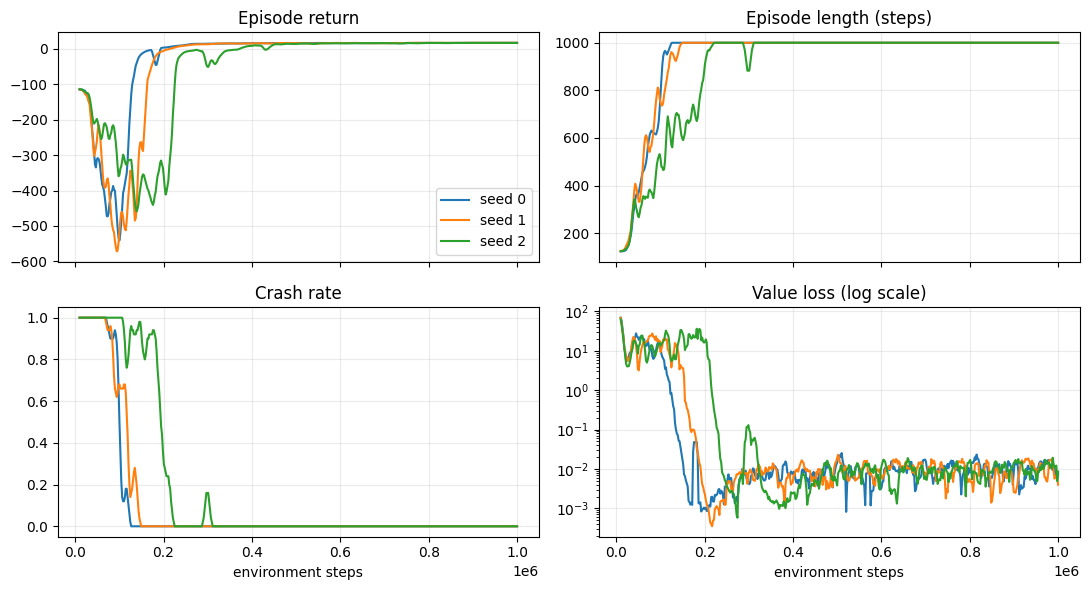

In [16]:
plot_training_history({f"seed {s}": r["history"] for s, r in seed_runs.items()})

<a id="evaluation"></a>

## 6. Evaluation

Every policy is evaluated on the same held-out seeds (1000 to 1019), which are never used in training, so the three algorithms face exactly the same 20 episodes. PPO is evaluated **deterministically** (the mean of the Gaussian, no exploration noise), as committed in Part B.

**6.1 Baselines: what does a policy that learns nothing score?** A learned policy is only useful if it beats these.
- `altitude_hold`: a hand-coded proportional controller on altitude.
- `random`: small random actions (scale 0.3 of the action range), not uniform over [-1, 1].
- `hover (zero action)`: always sends 0, so the inner controller simply holds position. At L0 this is the bar to beat.

In [17]:
from agroflight.evaluation.evaluate_policy import evaluate
from agroflight.baselines import altitude_hold_action, random_action

eval_env = gym.make(ENV_ID, level=EXPERIMENT["level"])
rng = np.random.default_rng(0)
baselines = {
    "altitude_hold": altitude_hold_action,
    "random": lambda obs: random_action(eval_env.action_space, rng),
    "hover (zero action)": lambda obs: np.zeros(4, dtype=np.float32),
}
for name, policy in baselines.items():
    RESULTS["evaluation"]["baselines"][name] = evaluate(policy, seeds=EXPERIMENT["eval_seeds"], env=eval_env)

for name, st in RESULTS["evaluation"]["baselines"].items():
    print(f"{name:<20} reward {st['mean_reward']:8.1f}  crash {st['crash_rate']:.0%}  finish {st['finish_rate']:.0%}")


altitude_hold        reward     19.8  crash 0%  finish 0%
random               reward      6.5  crash 0%  finish 0%
hover (zero action)  reward     14.9  crash 0%  finish 0%


**6.2 Load the trained policy.** Turns the saved checkpoint into a function `obs -> action`. The network is rebuilt, the weights are loaded, and the action is the output of `actor_mean` directly, without sampling from the Gaussian.

In [18]:
def load_ppo_policy(tag):
    """Rebuild the network, load its weights and return a DETERMINISTIC policy obs -> action."""
    agent = Agent(obs_dim=14, act_dim=4)
    load_checkpoint(agent, tag=tag)
    agent.eval()

    def policy(obs):
        obs = torch.as_tensor(obs, dtype=torch.float32).unsqueeze(0)   # (14,) -> (1, 14)
        with torch.no_grad():
            action = agent.actor_mean(obs)                             # Gaussian mean: no sampling
        return action.squeeze(0).numpy()                               # (1, 4) -> (4,)
    return policy


**6.3 Evaluate PPO at each difficulty level.** Each level gets its own environment. Add a level to the list once PPO clears the previous one (success criterion in Section 1).

In [19]:
def evaluate_at_level(policy, level):
    env = gym.make(ENV_ID, level=level)      # each level gets its own env: no hidden state
    try:
        return evaluate(policy, seeds=EXPERIMENT["eval_seeds"], env=env)
    finally:
        env.close()

ppo_policy = load_ppo_policy(tag=RUN_TAG)
for level in [0]:                            # add levels as PPO clears them
    st = evaluate_at_level(ppo_policy, level)
    RESULTS["evaluation"]["levels"][f"L{level}"] = st
    print(f"PPO @ L{level:<14} reward {st['mean_reward']:8.1f}  crash {st['crash_rate']:.0%}  "
          f"finish {st['finish_rate']:.0%}  |alt err| {st['mean_abs_alt_error']:.3f} m")


PPO @ L0              reward     19.9  crash 0%  finish 0%  |alt err| 0.003 m


<a id="results"></a>

## 7. Results

In [20]:
import pandas as pd

rows = []
for name, st in RESULTS["evaluation"]["baselines"].items():
    rows.append({"policy": name, **st})
for level, st in RESULTS["evaluation"]["levels"].items():
    rows.append({"policy": f"PPO @ {level}", **st})

cols = ["mean_reward", "std_reward", "crash_rate", "finish_rate", "mean_steps", "mean_abs_alt_error", "n_episodes"]
df = pd.DataFrame(rows).set_index("policy")[cols]
display(df.round(3))

,mean_reward,std_reward,crash_rate,finish_rate,mean_steps,mean_abs_alt_error,n_episodes
policy,,,,,,,
altitude_hold,19.781,0.240,0.0,0.0,1000.0,0.003,20
random,6.485,8.028,0.0,0.0,1000.0,0.056,20
hover (zero action),14.862,5.623,0.0,0.0,1000.0,0.042,20
PPO @ L0,19.860,0.114,0.0,0.0,1000.0,0.003,20


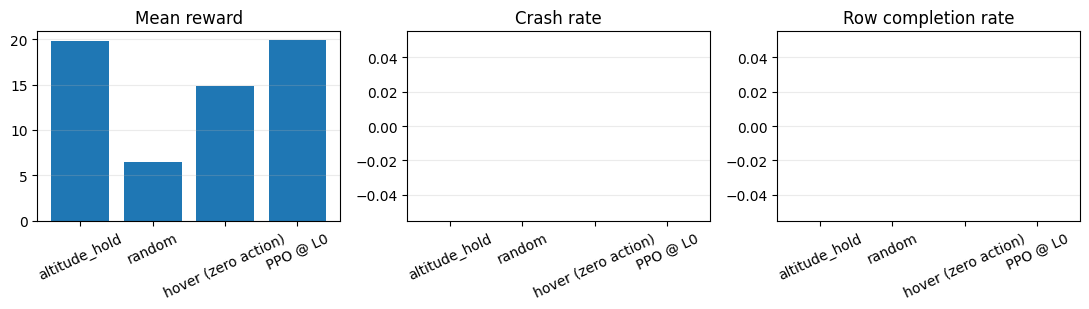

results saved to /Users/nelkitchavezcalona/Projects/UTS/RL/Reinforcement Learning - AT3/agroflight-rl/results/ppo_25609227.json


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, col, title in zip(axes, ["mean_reward", "crash_rate", "finish_rate"],
                          ["Mean reward", "Crash rate", "Row completion rate"]):
    ax.bar(df.index, df[col])
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

path = save_results(RESULTS)
print("results saved to", path)
if BACKUP_TO_DRIVE:
    backup_to_drive([RESULTS_DIR, CHECKPOINT_DIR])

<div style="border-left:4px solid rgb(147,105,28);background:rgba(147,105,28,0.10);padding:10px 14px;border-radius:0 8px 8px 0;margin:6px 0"><b>Write here.</b> State the headline result in one sentence: the highest level cleared and the samples it needed. Compare against both baselines and against your success criterion from Section 1. Report what did not work as well as what did.</div>

<a id="discussion"></a>

## 8. Discussion

<div style="border-left:4px solid rgb(147,105,28);background:rgba(147,105,28,0.10);padding:10px 14px;border-radius:0 8px 8px 0;margin:6px 0"><b>Write here.</b> <ul><li>Was training stable across seeds? Show the spread, not just the best run.</li><li>Did the reward behave as intended, or did you see reward hacking (for example hovering in place)? Check the viewer, not only the number.</li><li>Where did the algorithm fail, and is that the algorithm, the reward, or the environment?</li><li>Limits: MuJoCo has no rotor ground effect or canopy turbulence; wind is observable; single environment.</li><li>What would you try next with more time?</li></ul></div>

<a id="contribution"></a>

## 9. Contribution and reproducibility

<div style="border-left:4px solid rgb(147,105,28);background:rgba(147,105,28,0.10);padding:10px 14px;border-radius:0 8px 8px 0;margin:6px 0"><b>Write here.</b> Contribution statement (marks are split by individual contribution). Fill in the table.</div>

| | |
|---|---|
| **My contribution** | *what Nelkit built, ran and wrote* |
| **Shared work with teammates** | *environment rework, evaluation harness, viewer, report sections* |
| **AI assistance used** | *which tool, for what, and what you verified yourself* |

In [22]:
import platform
print("python    :", platform.python_version())
print("torch     :", torch.__version__)
print("numpy     :", np.__version__)
print("gymnasium :", gym.__version__)
print("mujoco    :", mujoco.__version__)
print("git commit:", git_commit())
print("train seed:", EXPERIMENT["train_seed"], "| eval seeds:", EXPERIMENT["eval_seeds"][0], "to", EXPERIMENT["eval_seeds"][-1])
print("notebook wall-clock so far: %.0f s" % (time.time() - NOTEBOOK_T0))

python    : 3.11.4
torch     : 2.11.0
numpy     : 2.4.4
gymnasium : 1.3.0
mujoco    : 3.14.0
git commit: 3bc550f
train seed: 0 | eval seeds: 1000 to 1019
notebook wall-clock so far: 3843 s


### References

1. Schulman, J., Wolski, F., Dhariwal, P., Radford, A., Klimov, O. (2017). Proximal Policy Optimization Algorithms. arXiv:1707.06347.
2. Schulman, J., Moritz, P., Levine, S., Jordan, M., Abbeel, P. (2016). High-Dimensional Continuous Control Using Generalized Advantage Estimation. ICLR. arXiv:1506.02438.
3. Huang, S. et al. (2022). CleanRL: High-quality Single-file Implementations of Deep Reinforcement Learning Algorithms. JMLR 23(274).
4. Todorov, E., Erez, T., Tassa, Y. (2012). MuJoCo: A physics engine for model-based control. IROS.
5. Google DeepMind. MuJoCo Menagerie: Skydio X2 model (Apache-2.0). github.com/google-deepmind/mujoco_menagerie.
6. Towers, M. et al. (2024). Gymnasium: A Standard Interface for Reinforcement Learning Environments. arXiv:2407.17032.